# 数値計算演習1：球対称質量モデル

**Ryden, *Celestial and Stellar Dynamics*, §6.4**

この Notebook では、Ryden §6.4 の球対称系を題材として、**数値積分（numerical integration）**の基本を学びます。中心となるモデルは §6.4.2 の **Plummer 密度分布（Plummer density profile）**です。

宇宙流体・重力多体系シミュレーションに進む準備として、積分値の求め方と検証を学びます。補足ではセル平均と粒子の初期位置分布との関係を紹介しますが、新たな計算コードは追加しません。

## 学習目標

1. 球対称な密度分布から内包質量を求める問題について、数値積分の被積分関数と積分区間を設定できる。
2. 左長方形則、中点則、台形則、Simpson 則の近似の考え方を説明し、Python で実装できる。
3. 累積積分を用いて、積分上限が異なる複数の積分値を効率よく計算できる。
4. 解析解との比較と格子収束試験から、各積分公式の誤差と収束次数 $p$ を評価できる。
5. 離散化誤差と丸め誤差を区別し、格子を細かくしても精度が向上しなくなる理由を説明できる。

この Notebook では、本文の学習目標に加えて、Hernquist・NFW 分布への数値積分法の適用を発展課題として扱います。

この Notebook では、無次元単位
$$
G=M=a=1
$$
を用います。ここで $M$ は Plummer 球の全質量、$a$ はスケール半径（scale radius）です。

> **参照箇所:** Ryden §6.4.2、特に式(6.101), (6.102), (6.107), (6.108)。  
> §6.4.3 の二重べき乗密度分布（double power-law profile）は最後の発展課題で扱います。

### 数値計算法の参考

数値積分については、幸谷智紀『Python数値計算プログラミング』第12章、特に §12.5 の Newton--Cotes 型積分公式を参考にします。この Notebook では、左長方形則・中点則を基礎から導入したうえで、台形則と Simpson 則へ進みます。

## 実行順序とテキストとの対応

この Notebook は単独で、上から順に実行できます。モデルのパラメータを変更した場合は、**カーネルを再起動し、変更した設定を保存してから全セルを実行**してください。途中のセルだけを実行すると、初期条件・解析解・加速度に古い値が残る場合があります。

対応する導出はテキスト第1章にあります。以下では節名で参照します。小さな配列や1ステップの確認を挟みますが、元の完成コードは残しています。短い自作部分は新しいセルに書き、続く完成例とは別に実行してください。

| テキストの内容 | Notebook 1 の節名 |
| --- | --- |
| Plummer 密度分布と解析解 | 「Plummer 球」「密度分布と被積分関数」 |
| 数値積分公式 | 「数値積分法」「4つの積分法の比較」 |
| 収束次数 | 「収束試験」 |
| 離散化誤差と丸め誤差 | 「Simpson 則と丸め誤差」 |
| 累積積分 | 「内包質量プロファイル」 |
| 円運動速度 | 「円運動速度」 |
| セル平均の脚注／高次元の積分とモンテカルロ積分の補足 | 「セル平均と中点則」「高次元の積分とモンテカルロ積分」 |
| 別の球対称モデル | 「発展課題：Hernquist・NFW 分布」 |




## 1. Plummer 球

Ryden §6.4.2 のコア型べき乗密度分布は
$$
\rho(r)=\frac{\rho_c}{\left(1+r^2/r_c^2\right)^{\beta/2}}
$$
です。$\beta=5$ の場合が Plummer 密度分布です。

ここでは $a=r_c$ と書き、全質量を $M$ とすると、
$$
\rho(r)=\frac{3M}{4\pi a^3}
\left(1+\frac{r^2}{a^2}\right)^{-5/2}.
$$

球対称系では、半径 $r$ より内側の質量は
$$
M(<r)=4\pi\int_0^r \rho(r')\,r'^2\,dr'
$$
です。

Plummer 密度分布ではこの積分を解析的に計算でき、
$$
M_{\rm exact}(<r)
=
M\frac{(r/a)^3}{\left[1+(r/a)^2\right]^{3/2}}
$$
となります。

この解析解を、数値積分の検証に使います。関数を呼び出すときには、最初に設定した物理パラメータ `M`, `a`（必要な場合は `G`）を引数として明示的に渡します。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 無次元単位
G = 1.0
M = 1.0
a = 1.0

# Okabe–Ito 配色
OI = {
    "orange": "#E69F00",
    "sky": "#56B4E9",
    "green": "#009E73",
    "yellow": "#F0E442",
    "blue": "#0072B2",
    "vermillion": "#D55E00",
    "purple": "#CC79A7",
    "black": "#000000",
}

plt.rcParams["figure.figsize"] = (6.5, 4.5)
plt.rcParams["font.size"] = 11


## 補足：この Notebook で使う NumPy の配列表記

Python の基本文法は既習であることを前提としますが、数値計算でよく使う NumPy の配列操作だけを最初に確認しておきます。

| 表記 | 意味 |
|---|---|
| `a[:-1]` | 最後の要素を除いた配列 |
| `a[1:]` | 最初の要素を除いた配列 |
| `a[1:-1:2]` | 端点を除き、添字1から1つおきに取り出す |
| `mask = a > 0` | 条件を満たす要素が `True` になる真偽値配列 |
| `np.diff(a)` | 隣り合う要素の差 $a_{i+1}-a_i$ |
| `np.cumsum(a)` | 左から順に足し上げた累積和 |

NumPy の配列演算を使うと、for ループを書かずに複数要素をまとめて処理できる場合があります。本 Notebook では、**数式とコードの対応が見えやすい場合に配列演算を利用**します。

### 無次元量から物理単位へ

Plummer モデルの長さ・質量の基準を $a$ と $M$ に取ると、速度・時間・ポテンシャルの単位は
$$
 v_\ast=\sqrt{GM/a},\qquad t_\ast=\sqrt{a^3/(GM)},\qquad \Phi_\ast=GM/a
$$
です。無次元の結果にこれらを掛ければ物理単位へ戻せます。例えば $\hat v=0.5$ は $v=0.5v_\ast$、$\hat t=10$ は $t=10t_\ast$ を表します。数値パラメータを変更する実験では、使用する基準単位を固定したままモデルを変更するのか、単位を取り直すのかを区別します。

**導出：長さ・質量の規格化はテキスト第1章「解析的な内包質量」、速度の単位は「内包質量と円運動速度」を参照してください。時間・ポテンシャルの単位は第3章「Plummer 球の重力場と軌道計算の準備」で扱います。**

In [2]:
def rho_plummer(r, M, a):
    return 3.0 * M / (4.0 * np.pi * a**3) * (1.0 + (r / a)**2)**(-2.5)

def mass_plummer_exact(r, M, a):
    s = r / a
    return M * s**3 / (1.0 + s**2)**1.5

def dMdr_plummer(r, M, a):
    return 4.0 * np.pi * r**2 * rho_plummer(r, M, a)

def vcirc_from_mass(r, menc, G):
    vc = np.zeros_like(r, dtype=float)

    # r=0 では G M(<r)/r が 0/0 になるため、r>0 の要素だけを計算する。
    # 比較演算 r > 0.0 は、各要素が True/False の真偽値配列を返す。
    mask = r > 0.0
    vc[mask] = np.sqrt(G * menc[mask] / r[mask])
    return vc



## 2. 密度分布と被積分関数

数値積分するのは $\rho(r)$ そのものではなく、
$$
\frac{dM}{dr}=4\pi r^2\rho(r)
$$
です。

### 実行前の確認

- $r\ll a$ では $\rho(r)$ はどのような振る舞いをするでしょうか。
- $r\gg a$ では $\rho\propto r^n$ の $n$ はいくつでしょうか。
- $dM/dr=4\pi r^2\rho(r)$ は中心と外側でどのように振る舞うでしょうか。


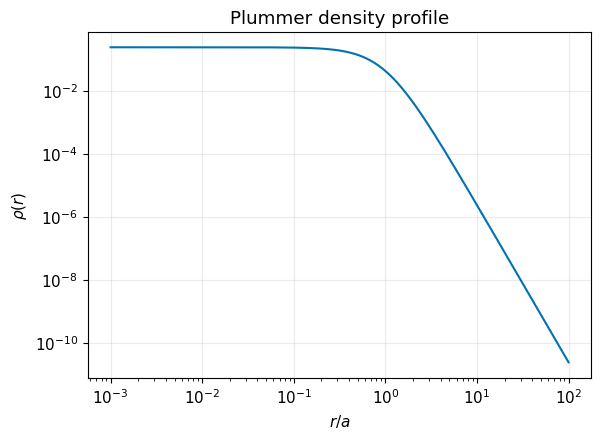

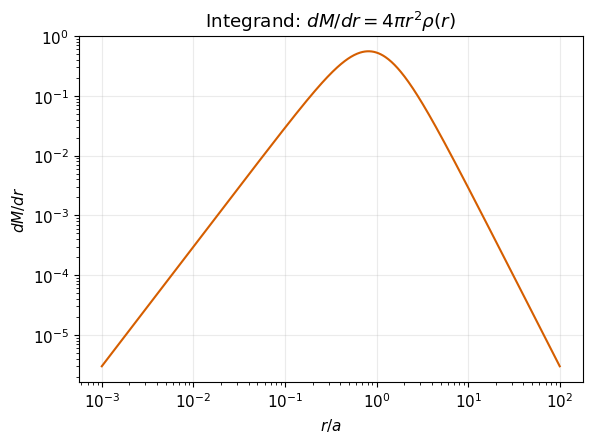

In [3]:
r_plot = a * np.logspace(-3, 2, 600)
rho_plot = rho_plummer(r_plot, M, a)
dMdr_plot = dMdr_plummer(r_plot, M, a)

fig, ax = plt.subplots()
ax.loglog(r_plot / a, rho_plot, color=OI["blue"])
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$\rho(r)$")
ax.set_title("Plummer density profile")
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots()
ax.loglog(r_plot / a, dMdr_plot, color=OI["vermillion"])
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$dM/dr$")
ax.set_title(r"Integrand: $dM/dr = 4\pi r^2\rho(r)$")
ax.grid(alpha=0.25)
plt.show()



# 3. 数値積分法

ここでは、固定した半径 $r_{\rm eval}$ までの質量
$$
M(<r_{\rm eval})=\int_0^{r_{\rm eval}} \frac{dM}{dr}\,dr
$$
を4種類の数値積分法で求めます。

積分公式を説明するときは $x$ を一般の積分変数とし、区間 $[x_0,x_N]$ を $N$ 個に等分します。格子幅と格子点を
$$
h=\frac{x_N-x_0}{N},\qquad x_i=x_0+ih
$$
とします。次のコードでは、引数 `x0` と `xN` がそれぞれ積分の下端 $x_0$ と上端 $x_N$ に対応します。内包質量の計算では、下端は0、上端は $r_{\rm eval}$ です。

## 3.1 左長方形則

各小区間の左端の値を使います。
$$
I_{\rm left}
=
h\sum_{i=0}^{N-1}f(x_i).
$$

一般に誤差は
$$
O(h)
$$
です。

## 3.2 中点則

各小区間の中点
$$
x_{i+1/2}=x_i+\frac{h}{2}
$$
で関数を評価します。
$$
I_{\rm mid}
=
h\sum_{i=0}^{N-1}f(x_{i+1/2}).
$$

一般に誤差は
$$
O(h^2)
$$
です。

### 補足：セル平均と中点則

格子法の流体計算で用いる有限体積法では、密度などのセル平均値を未知数とする。
一次元の Cartesian 座標で、幅 $h$ のセルを中心のまわりに対称に取ると、滑らかな関数のセル平均とセル中心の値との差は $O(h^2)$ となります。
この関係は、中点則の誤差と同じように Taylor 展開から説明できる（参考：松本ほか『輻射電磁流体シミュレーションの基礎』）。

## 3.3 台形則

各小区間で関数を直線近似します。
$$
I_{\rm trap}
=
h\left[
\frac{1}{2}f(x_0)
+\sum_{i=1}^{N-1}f(x_i)
+\frac{1}{2}f(x_N)
\right].
$$

一般に誤差は
$$
O(h^2)
$$
です。

## 3.4 Simpson 則

2区間ごとに二次多項式で近似します。
$$
I_{\rm Simpson}
=
\frac{h}{3}
\left[
f(x_0)+f(x_N)
+4\sum_{\substack{i=1\\i:\,\mathrm{odd}}}^{N-1}f(x_i)
+2\sum_{\substack{i=2\\i:\,\mathrm{even}}}^{N-2}f(x_i)
\right].
$$

滑らかな関数では誤差は
$$
O(h^4)
$$
です。

**Simpson 則では $N$ は偶数でなければなりません。**


**導出：テキスト第1章「基本的な数値積分公式」。**

In [4]:
def left_rule(func, x0, xN, N):
    h = (xN - x0) / N
    x = x0 + np.arange(N) * h
    return h * np.sum(func(x))

def midpoint_rule(func, x0, xN, N):
    h = (xN - x0) / N
    x_mid = x0 + (np.arange(N) + 0.5) * h
    return h * np.sum(func(x_mid))

def trapezoid_rule(func, x0, xN, N):
    h = (xN - x0) / N
    x = np.linspace(x0, xN, N + 1)
    y = func(x)
    return h * (0.5 * y[0] + np.sum(y[1:-1]) + 0.5 * y[-1])

def simpson_rule(func, x0, xN, N):
    if N % 2 != 0:
        raise ValueError("Simpson 則では N を偶数にしてください。")
    h = (xN - x0) / N
    x = np.linspace(x0, xN, N + 1)
    y = func(x)

    # y[開始:終了:ステップ] の3番目の指定で、1つおきの要素を取り出す。
    # y[1:-1:2] -> y[1], y[3], y[5], ...：Simpson 則の奇数番号の項
    # y[2:-1:2] -> y[2], y[4], y[6], ...：Simpson 則の偶数番号の項
    # 端点 y[0], y[N] は上の2つの和には含めず、別に足す。
    odd_sum = np.sum(y[1:-1:2])
    even_sum = np.sum(y[2:-1:2])
    return h / 3.0 * (y[0] + y[-1] + 4.0 * odd_sum + 2.0 * even_sum)



## 4. 4つの積分法の比較

ここでは
$$
r_{\rm eval}=a
$$
として、$M(<a)$ を4つの方法で計算します。

この半径では、今回の滑らかな被積分関数に対して4つの方法の漸近的な収束次数が比較的明瞭に現れます。


In [5]:
r_eval = 1.0 * a
N = 40
func = lambda r: dMdr_plummer(r, M, a)

m_left = left_rule(func, 0.0, r_eval, N)
m_mid = midpoint_rule(func, 0.0, r_eval, N)
m_trap = trapezoid_rule(func, 0.0, r_eval, N)
m_simp = simpson_rule(func, 0.0, r_eval, N)
m_exact_eval = mass_plummer_exact(r_eval, M, a)

print(f"解析値                : {m_exact_eval:.12f}")
print(f"左長方形則            : {m_left:.12f}   誤差 = {abs(m_left - m_exact_eval):.3e}")
print(f"中点則                : {m_mid:.12f}   誤差 = {abs(m_mid - m_exact_eval):.3e}")
print(f"台形則                : {m_trap:.12f}   誤差 = {abs(m_trap - m_exact_eval):.3e}")
print(f"Simpson 則            : {m_simp:.12f}   誤差 = {abs(m_simp - m_exact_eval):.3e}")


解析値                : 0.353553390593
左長方形則            : 0.346910451143   誤差 = 6.643e-03
中点則                : 0.353560298293   誤差 = 6.908e-06
台形則                : 0.353539577216   誤差 = 1.381e-05
Simpson 則            : 0.353553401385   誤差 = 1.079e-08



## 演習1：4つの積分法の比較

1. `N = 10`, `20`, `40`, `80` と変えて結果を比較してください。
2. 左長方形則は他の方法より誤差が大きいでしょうか。
3. 中点則と台形則はどちらも2次精度ですが、今回の積分ではどちらの誤差が小さいでしょうか。
4. Simpson 則で `N = 41` とした場合に何が起こるか確認してください。



# 5. 収束試験

数値積分法の精度を、格子幅 $h$ を変えて調べます。

誤差を
$$
\epsilon=
\left|
M_{\rm numerical}(<r_{\rm eval})
-
M_{\rm exact}(<r_{\rm eval})
\right|
$$
とします。

理論的には
$$
\epsilon\propto h^p
$$
で、

| 方法 | 理論的な収束次数 $p$ |
|---|---:|
| 左長方形則 | 1 |
| 中点則 | 2 |
| 台形則 | 2 |
| Simpson 則 | 4 |

です。

両対数プロット（log-log plot）で $\epsilon$ と $h$ の関係を描くと、傾きが収束次数 $p$ になります。


### 台形則による収束次数の確認

先に、1つの方法を通常の `for` ループで計算します。区間数を2倍にすると格子幅は半分になるため、連続する2格子から
$$
 p_{\rm obs}=\frac{\log[\epsilon(h)/\epsilon(h/2)]}{\log 2}
$$
を求められます。台形則では誤差がほぼ4分の1になり、$p_{\rm obs}\simeq2$ となるはずです。

**導出：テキスト第1章「収束次数の測定」。**

In [6]:
N_intro = np.array([10, 20, 40, 80, 160, 320])
trap_errors_intro = []
for n_intervals in N_intro:
    mass_value = trapezoid_rule(func, 0.0, r_eval, int(n_intervals))
    trap_errors_intro.append(abs(mass_value - m_exact_eval))
trap_errors_intro = np.array(trap_errors_intro)
# 隣り合う格子で h が半分になるので、誤差比の log2 が収束次数。
for k in range(len(N_intro) - 1):
    p_pair = np.log(trap_errors_intro[k] / trap_errors_intro[k + 1]) / np.log(2.0)
    print(f"区間数 {N_intro[k]:3d} → {N_intro[k+1]:3d}: 誤差比 = {trap_errors_intro[k]/trap_errors_intro[k+1]:.4f}, 収束次数 = {p_pair:.4f}")

区間数  10 →  20: 誤差比 = 4.0094, 収束次数 = 2.0034
区間数  20 →  40: 誤差比 = 4.0023, 収束次数 = 2.0008
区間数  40 →  80: 誤差比 = 4.0006, 収束次数 = 2.0002
区間数  80 → 160: 誤差比 = 4.0001, 収束次数 = 2.0001
区間数 160 → 320: 誤差比 = 4.0000, 収束次数 = 2.0000


次のセルでは同じ処理を4つの方法へ広げます。辞書の各値は「区間数を渡すと積分値を返す関数」です。`lambda N: ...` はその関数を短く書いた表現であり、数値計算法そのものは上と変わりません。

**次数の測定に使う範囲：** 離散化誤差が支配して規則的に減少する格子だけを選びます。丸め誤差で停滞した点や計算上0となった点は除きます。正の誤差だけに絞ることは必要条件ですが、丸め誤差領域を除くにはそれだけでは不十分です。0を小さな正数へ置換して次数を測ってはいけません。

In [7]:
N_values = np.array([10, 20, 40, 80, 160, 320])
h_values = r_eval / N_values

methods = {
    "Left rectangle": lambda N: left_rule(func, 0.0, r_eval, N),
    "Midpoint": lambda N: midpoint_rule(func, 0.0, r_eval, N),
    "Trapezoidal": lambda N: trapezoid_rule(func, 0.0, r_eval, N),
    "Simpson": lambda N: simpson_rule(func, 0.0, r_eval, N),
}

errors = {}
orders = {}

for name, method in methods.items():
    err = np.array([abs(method(int(N)) - m_exact_eval) for N in N_values])
    errors[name] = err

    # 誤差 ε ∝ h^p なら log ε = p log h + 定数。
    # np.polyfit(..., 1) は [傾き, 切片] を返すので、[0] が収束次数 p。
    orders[name] = np.polyfit(np.log(h_values), np.log(err), 1)[0]

method_names_ja = {
    "Left rectangle": "左長方形則",
    "Midpoint": "中点則",
    "Trapezoidal": "台形則",
    "Simpson": "Simpson 則",
}

for name in methods:
    print(f"{method_names_ja[name]:10s}: 測定した収束次数 = {orders[name]:.3f}")


左長方形則     : 測定した収束次数 = 1.002
中点則       : 測定した収束次数 = 2.001
台形則       : 測定した収束次数 = 2.001
Simpson 則 : 測定した収束次数 = 4.001


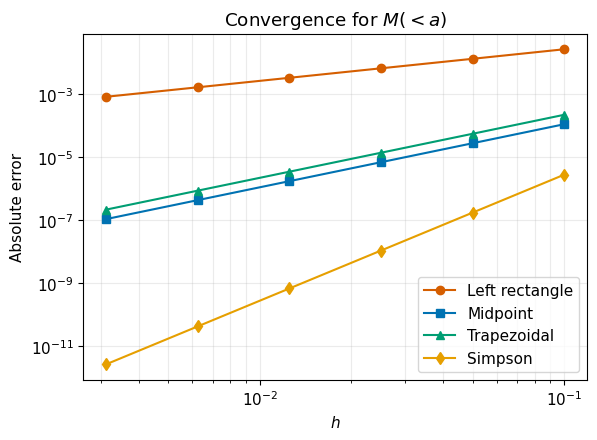

In [8]:
fig, ax = plt.subplots()
ax.loglog(h_values, errors["Left rectangle"], "o-", color=OI["vermillion"], label="Left rectangle")
ax.loglog(h_values, errors["Midpoint"], "s-", color=OI["blue"], label="Midpoint")
ax.loglog(h_values, errors["Trapezoidal"], "^-", color=OI["green"], label="Trapezoidal")
ax.loglog(h_values, errors["Simpson"], "d-", color=OI["orange"], label="Simpson")
ax.set_xlabel(r"$h$")
ax.set_ylabel("Absolute error")
ax.set_title(r"Convergence for $M(<a)$")
ax.legend()
ax.grid(alpha=0.25, which="both")
plt.show()



## 演習2：収束次数の測定

1. 4つの方法について、測定した収束次数が理論値に近いか確認してください。
2. 最も粗い `N = 10` を除いて収束次数を再計算してください。
3. Simpson 則について `N = 320, 640, 1280, 2560, 5120, 10240` 程度まで増やしてください。いつまでも $h^4$ に比例して誤差が減り続けるでしょうか。
4. 誤差が $10^{-15}$ 程度に近づくと、離散化誤差より浮動小数点の丸め誤差が重要になります。このことを実際の数値から確認してください。
5. 数値計算で「高次の方法ほど常に良い」と単純には言えない理由を考えてください。


次数を再計算する際は、規則的に誤差が減る範囲を自分で選んでください。丸め誤差の確認用に追加した大きな `N` の点を、収束次数の当てはめへそのまま含めないでください。

### 離散化誤差と丸め誤差

数値積分公式では、Taylor 展開や補間の高次項を有限次数で打ち切るため、
その捨てた項に由来する**打ち切り誤差（truncation error）**が生じます。
1つの小区間（Simpson 則では2区間1組）に公式を適用したときの誤差を、**局所打ち切り誤差（local truncation error）**と呼びます。
積分範囲全体で得られる近似値の誤差は**大域誤差（global error）**です。本章の数値積分では、各区間の打ち切り誤差を合成した結果が、積分値の**離散化誤差（discretization error）**として現れます。

一方、浮動小数点演算では有限桁へ丸めるため**丸め誤差（round-off error）**が生じます。
また、有限の $r_{\max}$ で積分を止める「計算領域の打ち切り」は、ここでいう打ち切り誤差とは別です。


### Simpson 則と丸め誤差

4次精度という性質は、$h$ を小さくすれば無限に誤差が減ることを意味しません。倍精度浮動小数点では、十分細かい格子になると丸め誤差の影響が見えてきます。

次のセルでは $M(<a)$ の Simpson 積分を $N\sim10^4$ まで試し、誤差を数値と両対数グラフで確認します。離散化誤差が $h^4$ に従って減少した後、機械精度付近でその関係から外れる様子を確認してください。

$N=10240$ では、数値積分値と解析値が同じ浮動小数点数へ丸められるため、この計算では差が0になります。対数軸では0を表示できないので、グラフでは誤差が正の点だけを描きます。

N =    320, Simpson 則の誤差 = 2.634e-12
N =    640, Simpson 則の誤差 = 1.646e-13
N =   1280, Simpson 則の誤差 = 1.027e-14
N =   2560, Simpson 則の誤差 = 6.106e-16
N =   5120, Simpson 則の誤差 = 5.551e-17
N =  10240, Simpson 則の誤差 = 0.000e+00
N =  20480, Simpson 則の誤差 = 5.551e-17
機械イプシロン = 2.220e-16


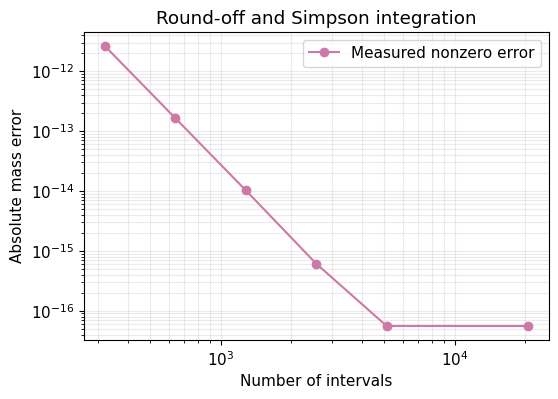

In [9]:
N_large = np.array([320, 640, 1280, 2560, 5120, 10240, 20480])
err_large = []

for N_i in N_large:
    val = simpson_rule(func, 0.0, r_eval, int(N_i))
    err_large.append(abs(val - m_exact_eval))

for N_i, err_i in zip(N_large, err_large):
    print(f"N = {N_i:6d}, Simpson 則の誤差 = {err_i:.3e}")

print(f"機械イプシロン = {np.finfo(float).eps:.3e}")

# 対数軸では誤差0を表示できないため、正の誤差だけを描く
err_plot = np.asarray(err_large)
positive = err_plot > 0

fig, ax = plt.subplots(figsize=(6.0, 4.0))
ax.loglog(N_large[positive], err_plot[positive], "o-", color=OI["purple"], label="Measured nonzero error")
ax.set_xlabel("Number of intervals")
ax.set_ylabel("Absolute mass error")
ax.set_title("Round-off and Simpson integration")
ax.grid(alpha=0.25, which="both")
ax.legend()
plt.show()


# 6. 内包質量プロファイル

4種類の積分法の違いを理解した後、$M(<r)$ のプロファイル全体を計算します。

ここでは **台形則** を標準として使います。理由は、

- 実装が単純
- 累積積分を作りやすい
- 不等間隔格子にも自然に拡張できる
- 滑らかな関数に対して2次精度

だからです。

各区間について
$$
\Delta M_i
\simeq
\frac{1}{2}
\left[
\left(\frac{dM}{dr}\right)_i+
\left(\frac{dM}{dr}\right)_{i+1}
\right]
(r_{i+1}-r_i)
$$
を累積します。


### 実装確認：小さな配列での台形面積

最初に、$r/a=0,0.5,1,1.5,2$ の5点で、各区間の質量 $\Delta M_i$ とその累積和を表示します。この粗い格子の目的は精度評価ではなく、長さ4の区間配列が長さ5の内包質量配列へ変わることを確認することです。

**自分で書く部分：** 次の例の後に新しいセルを作り、`np.cumsum` を使わず、$M_0=0$、$M_{i+1}=M_i+\Delta M_i$ の `for` ループを書いてください。入力は `r_small`, `area_small`、出力は `mass_small_loop` とします。`np.testing.assert_allclose(mass_small_loop, mass_small)` が通れば、配列の対応を確認できます。

**導出：テキスト第1章「累積積分による内包質量プロファイル」。**

In [10]:
r_small = np.linspace(0.0, 2.0 * a, 5)
f_small = dMdr_plummer(r_small, M, a)
area_small = 0.5 * (f_small[:-1] + f_small[1:]) * np.diff(r_small)
mass_small = np.concatenate(([0.0], np.cumsum(area_small)))
print("区間の質量 / M:", area_small / M)
print("格子点までの内包質量 / M:", mass_small / M)
print("区間の総和 / M:", np.sum(area_small) / M)
np.testing.assert_allclose(mass_small[-1], np.sum(area_small))
# 新しいセルに mass_small_loop を作り、mass_small と比較してください。

区間の質量 / M: [0.10733126 0.23991378 0.22120326 0.14228637]
格子点までの内包質量 / M: [0.         0.10733126 0.34724505 0.56844831 0.71073468]
区間の総和 / M: 0.7107346830624589


In [11]:
def cumulative_trapezoid_manual(x, y):
    """台形則で y(x) の累積積分を求める。

    result[i] は x[0] から x[i] までの積分値を表す。
    """
    result = np.zeros_like(x, dtype=float)

    # np.diff(x) は隣接点の間隔 x[i+1]-x[i] を一度に計算する。
    # 要素数は x より1つ少なくなる。
    dx = np.diff(x)

    # y[:-1] は最後を除いた配列、y[1:] は最初を除いた配列。
    # 両者を足すことで、各区間の隣り合う2点 y[i]+y[i+1] を一度に作る。
    area = 0.5 * (y[:-1] + y[1:]) * dx

    # np.cumsum(area) で台形の面積を左から順に積み上げる。
    # result[0]=0 は積分区間の幅が0であることに対応する。
    result[1:] = np.cumsum(area)
    return result

In [12]:
# N_profile は区間数ではなく格子点数。400点なら399区間になる。
N_profile = 400
r_max = 20.0 * a
r = np.linspace(0.0, r_max, N_profile)

rho = rho_plummer(r, M, a)
dMdr = dMdr_plummer(r, M, a)
m_num = cumulative_trapezoid_manual(r, dMdr)
m_exact = mass_plummer_exact(r, M, a)

print(f"M_num(< r_max)   = {m_num[-1]:.8f}")
print(f"M_exact(< r_max) = {m_exact[-1]:.8f}")
print(f"全質量 M          = {M:.8f}")


M_num(< r_max)   = 0.99626167
M_exact(< r_max) = 0.99626168
全質量 M          = 1.00000000



### 注意：有限の $r_{\max}$ と数値誤差の違い

$M(<r_{\max})$ が全質量 $M$ より少し小さいのは、必ずしも数値誤差ではありません。Plummer 球は無限遠まで広がっているため、有限の $r_{\max}$ の外側にも質量があります。

したがって、数値積分の精度を調べるときは
$$
M_{\rm num}(<r)
\quad \text{と} \quad
M_{\rm exact}(<r)
$$
を**同じ半径**で比較します。


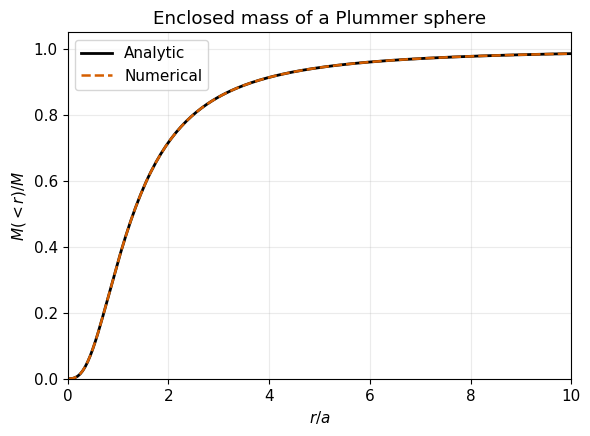

In [13]:
fig, ax = plt.subplots()
ax.plot(r / a, m_exact / M, color=OI["black"], lw=2.0, label="Analytic")
ax.plot(r / a, m_num / M, "--", color=OI["vermillion"], lw=1.8, label="Numerical")
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$M(<r)/M$")
ax.set_title("Enclosed mass of a Plummer sphere")
ax.set_xlim(0, 10)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.25)
plt.show()



## 演習3：質量プロファイル

1. 数値解と解析解がほぼ重なっていることを確認してください。
2. `N_profile = 50`, `100`, `200`, `400` と変えて違いを確認してください。
3. `r_max` を変えたとき、$M(<r_{\max})$ と全質量 $M$ の差がどう変わるか調べてください。
4. **離散化誤差** と有限の $r_{\max}$ による **計算領域の打ち切り** の違いを説明してください。



# 7. 円運動速度

Ryden 式(6.79) より、球対称系の円運動速度は
$$
v_{\rm circ}(r)=\sqrt{\frac{G M(<r)}{r}}
$$
です。

数値積分で求めた $M_{\rm num}(<r)$ から $v_{\rm circ}$ を計算し、解析的な $M_{\rm exact}(<r)$ を使った結果と比較します。


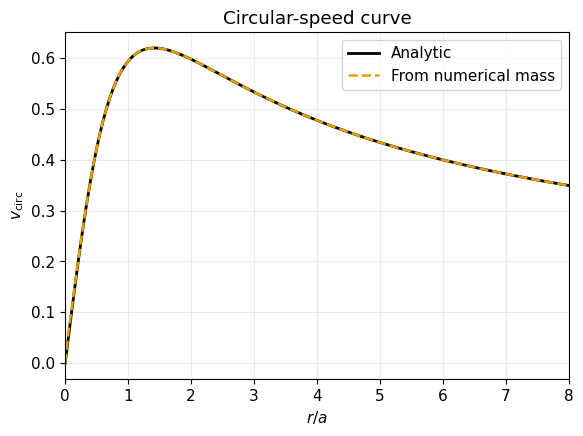

数値解の最大位置: r/a = 1.4035, v_circ = 0.620347
解析的な最大半径 sqrt(2) = 1.414214


In [14]:
vc_num = vcirc_from_mass(r, m_num, G)
vc_exact = vcirc_from_mass(r, m_exact, G)

fig, ax = plt.subplots()
ax.plot(r / a, vc_exact, color=OI["black"], lw=2.0, label="Analytic")
ax.plot(r / a, vc_num, "--", color=OI["orange"], lw=1.8, label="From numerical mass")
ax.set_xlabel(r"$r/a$")
ax.set_ylabel(r"$v_{\rm circ}$")
ax.set_title("Circular-speed curve")
ax.set_xlim(0, 8)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

i_peak = np.argmax(vc_num)
print(f"数値解の最大位置: r/a = {r[i_peak] / a:.4f}, v_circ = {vc_num[i_peak]:.6f}")
print(f"解析的な最大半径 sqrt(2) = {np.sqrt(2.0):.6f}")



## 演習4：円運動速度

1. $r\rightarrow0$ で $v_{\rm circ}\rightarrow0$ になる理由を、中心付近の $M(<r)$ の振る舞いから説明してください。
2. $r\gg a$ では $M(<r)\simeq M$ です。この極限で $v_{\rm circ}$ は $r$ の何乗に比例するでしょうか。
3. 数値的に求めた $v_{\rm circ}$ の最大位置を確認してください。解析的には $r=\sqrt{2}\,a$ で最大になります。


## 補足：高次元の積分とモンテカルロ積分

以下は本文第1章末の補足に対応する読み物です。新しい実装課題ではありません。
各方向を $n$ 分割する $d$ 次元の格子では、総評価点数はおよそ $N_{\rm eval}=n^d$ です。各方向で誤差が $h^p$ で減る積分公式を使うと、誤差はおおよそ $N_{\rm eval}^{-p/d}$ で減ります。

これに対し、積分領域から独立に点を抽出して関数値の平均から積分値を推定する方法を、**モンテカルロ積分**と呼びます。一様抽出した点 $x_k$ に対し、
$$
I=\int_{x_{\min}}^{x_{\max}} f(x)\,dx\simeq\frac{x_{\max}-x_{\min}}{N_{\rm samp}}\sum_{k=1}^{N_{\rm samp}}f(x_k)
$$
です。被積分関数の分散が有限なら、標準誤差は $N_{\rm samp}^{-1/2}$ に比例します。低次元で滑らかな積分では今回の積分公式が効率的ですが、高次元では乱数を用いる方法も選択肢になります。

### 重力多体系の初期位置分布

重力多体系シミュレーションで、等質量粒子の初期位置を作るときにも、乱数と内包質量を使う。
球対称分布の全質量を $M$ とし、$0<X<1$ の一様乱数を生成して $M(<r)/M=X$ を満たす半径 $r$ を求める。
この操作を**逆関数法（inverse transform sampling）**といいます。
半径の確率密度は $\rho(r)$ そのものではなく $4\pi r^2\rho(r)/M$ であり、方向も等方的に選ぶことで、密度分布 $\rho(r)$ に対応する粒子配置を作れる。
Plummer 球では上の Plummer 球の内包質量の式を逆に解き、
$$
 r=a\left(X^{-2/3}-1\right)^{-1/2}
$$
と求められます。
一般の密度分布では、累積積分で得た内包質量の表を逆にたどり、必要に応じて補間して半径を決める。
有限半径 $r_{\max}$ までの表を使う場合は、その半径までの質量で規格化し、$M(<r)=X M(<r_{\max})$ を満たす半径を求める。
これは位置分布の作成であり、平衡な初期条件を作るには、質量分布と整合する速度分布も別途与える必要がある。

粒子を独立に抽出すると、一定の半径内に入る粒子数の割合には統計的なゆらぎが残る。
その標準偏差は粒子数 $N_{\rm p}$ に対して $N_{\rm p}^{-1/2}$ に比例する。
これは乱数サンプリングのゆらぎであり、累積積分の離散化誤差や、その後の時間積分の誤差とは区別する。

**参考：** 三井田・須田『数値計算法』第9章、富阪ほか編『シミュレーション天文学』第6章。



# 発展課題：Hernquist・NFW 分布

Ryden §6.4.3 では二重べき乗密度分布
$$
\rho(r)=
\frac{\rho_s}
{(r/r_s)^\gamma(1+r/r_s)^{\beta-\gamma}}
$$
が導入されます。

代表例は

- Hernquist: $(\beta,\gamma)=(4,1)$
- NFW: $(\beta,\gamma)=(3,1)$

です。

ここでは、数値積分法の比較を終えた後なので、実用計算として台形則を使って内包質量を求めます。


以下のコードでは、Hernquist の質量・半径に `M, a` を渡し、NFW の質量スケール・半径に `M0, rs` を明示的に指定します。NFW の `M0` は全質量ではなく、内包質量を規格化する係数です。


In [15]:
def dMdr_hernquist(r, M, a):
    return 2.0 * M * a * r / (r + a)**3

def mass_hernquist_exact(r, M, a):
    return M * r**2 / (r + a)**2

def dMdr_nfw(r, M0, rs):
    s = r / rs
    return (M0 / rs) * s / (1.0 + s)**2

def mass_nfw_exact(r, M0, rs):
    s = r / rs
    return M0 * (np.log(1.0 + s) - s / (1.0 + s))


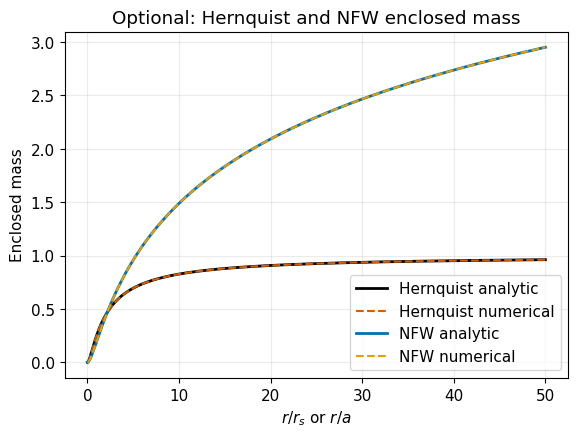

In [16]:
# 発展課題では Hernquist の M,a と、NFW の質量スケール M0・半径 rs を明示する。
r_ext = np.linspace(0.0, 50.0, 2000)
M0 = 1.0
rs = 1.0

m_h_num = cumulative_trapezoid_manual(r_ext, dMdr_hernquist(r_ext, M, a))
m_h_exact = mass_hernquist_exact(r_ext, M, a)

m_nfw_num = cumulative_trapezoid_manual(r_ext, dMdr_nfw(r_ext, M0, rs))
m_nfw_exact = mass_nfw_exact(r_ext, M0, rs)

fig, ax = plt.subplots()
ax.plot(r_ext, m_h_exact, color=OI["black"], lw=2.0, label="Hernquist analytic")
ax.plot(r_ext, m_h_num, "--", color=OI["vermillion"], label="Hernquist numerical")
ax.plot(r_ext, m_nfw_exact, color=OI["blue"], lw=2.0, label="NFW analytic")
ax.plot(r_ext, m_nfw_num, "--", color=OI["orange"], label="NFW numerical")
ax.set_xlabel(r"$r/r_s$ or $r/a$")
ax.set_ylabel("Enclosed mass")
ax.set_title("Optional: Hernquist and NFW enclosed mass")
ax.legend()
ax.grid(alpha=0.25)
plt.show()



## 発展課題

1. Hernquist 分布では $r\rightarrow\infty$ で内包質量が有限値へ収束することを確認してください。
2. NFW 分布では内包質量が非常にゆっくり増加し続けます。Ryden 式(6.121) と比較してください。
3. それぞれについて
   $$
   v_{\rm circ}(r)=\sqrt{\frac{GM(<r)}{r}}
   $$
   を計算し、回転曲線（rotation curve）の形を比較してください。
4. Plummer, Hernquist, NFW で中心付近の質量プロファイルがどのように異なるか説明してください。

> **注意:** NFW モデルは全質量が有限ではないので、上では $M_0=4\pi\rho_s r_s^3$ を質量スケール（mass scale）として $M_0=1$ に設定しています。



# まとめ

この Notebook では、球対称系について
$$
\boxed{
\rho(r)
\longrightarrow
M(<r)
\longrightarrow
v_{\rm circ}(r)
}
$$
という流れを数値計算しました。

数値計算法としては、

- 左長方形則
- 中点則
- 台形則
- Simpson 則
- 収束試験
- 非常に細かい格子での丸め誤差
- 累積数値積分

を学びました。

特に、
$$
\epsilon\propto h^p
$$
として数値的に収束次数を測り、理論的な
$$
p=1,\ 2,\ 2,\ 4
$$
と比較しました。

次の Notebook では、同じ Plummer 密度分布を使い、
$$
\boxed{
\rho(r)
\longrightarrow
\Phi(r)
\longrightarrow
g_r(r)
}
$$
を扱います。Poisson 方程式を有限差分化し、重力ポテンシャルを数値的に求めます。


第1章の数値積分を薄い円盤へ広げる内容は、テキスト付録A「軸対称円盤の質量積分と回転曲線」と Notebook A で扱います。
